# Telco Customer Churn Analysis

## Project Overview

This project analyzes customer churn in a telecommunications company to identify customer retention patterns and understand the factors associated with customer churn.

## Objectives

- Perform data cleaning and data validation.
- Explore customer demographics and service usage.
- Analyze churn rates across different customer groups.
- Identify factors associated with higher customer churn.
- Generate insights to support customer retention strategies.

## Tools & Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook

## Dataset

Telco Customer Churn Dataset

## Analysis

Exploratory Data Analysis (EDA), missing-value analysis, customer segmentation, churn rate analysis, and data visualization.



In [72]:
import pandas as pd

In [73]:
import numpy as np

In [ ]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [75]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [76]:
df.shape

(7043, 21)

In [77]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [78]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [79]:
(df['TotalCharges'].str.strip() == '').sum()

np.int64(11)

In [80]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [81]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [82]:
df['TotalCharges'].dtype

dtype('float64')

In [83]:
df.duplicated().sum()


np.int64(0)

In [84]:
df['customerID'].duplicated().sum()

np.int64(0)

In [85]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [87]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [88]:
df['Churn'].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [89]:
pd.crosstab(df['Contract'], df['Churn'])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [90]:
pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [91]:
pd.crosstab(df['PaymentMethod'], df['Churn'])

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


In [92]:
pd.crosstab(df['PaymentMethod'],df['Churn'],normalize='index')*100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


In [93]:
pd.crosstab(df['InternetService'],df['Churn'])

Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


In [94]:
pd.crosstab(df['InternetService'],df['Churn'],normalize='index')*100

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


In [95]:
pd.crosstab(df['OnlineSecurity'], df['Churn'])

Churn,No,Yes
OnlineSecurity,,
No,2037,1461
No internet service,1413,113
Yes,1724,295


In [96]:
pd.crosstab(df['OnlineSecurity'], df['Churn'], normalize='index') * 100

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


In [97]:
result = pd.crosstab(df['TechSupport'], df['Churn'])
result['Total'] = result.sum(axis=1)
result['Churn_Rate_%'] = (result['Yes'] / result['Total']) * 100
result

Churn,No,Yes,Total,Churn_Rate_%
TechSupport,,,,
No,2027,1446,3473,41.635474
No internet service,1413,113,1526,7.404980
Yes,1734,310,2044,15.166341


In [98]:
result = pd.crosstab(df['OnlineBackup'], df['Churn'])
result['Total'] = result.sum(axis=1)
result['Churn_Rate_%'] = (result['Yes'] / result['Total']) * 100
result

Churn,No,Yes,Total,Churn_Rate_%
OnlineBackup,,,,
No,1855,1233,3088,39.928756
No internet service,1413,113,1526,7.404980
Yes,1906,523,2429,21.531494


In [99]:
result = pd.crosstab(df['DeviceProtection'], df['Churn'])
result['Total'] = result.sum(axis=1)
result['Churn_Rate_%'] = (result['Yes'] / result['Total']) * 100
result

Churn,No,Yes,Total,Churn_Rate_%
DeviceProtection,,,,
No,1884,1211,3095,39.127625
No internet service,1413,113,1526,7.404980
Yes,1877,545,2422,22.502064


In [100]:
result = pd.crosstab(df['StreamingTV'], df['Churn'])
result['Total'] = result.sum(axis=1)
result['Churn_Rate_%'] = (result['Yes'] / result['Total']) * 100
result

Churn,No,Yes,Total,Churn_Rate_%
StreamingTV,,,,
No,1868,942,2810,33.523132
No internet service,1413,113,1526,7.404980
Yes,1893,814,2707,30.070188


In [101]:
result = pd.crosstab(df['StreamingMovies'], df['Churn'])
result['Total'] = result.sum(axis=1)
result['Churn_Rate_%'] = (result['Yes'] / result['Total']) * 100
result

Churn,No,Yes,Total,Churn_Rate_%
StreamingMovies,,,,
No,1847,938,2785,33.680431
No internet service,1413,113,1526,7.404980
Yes,1914,818,2732,29.941435


In [102]:
result = pd.crosstab(df['PaperlessBilling'], df['Churn'])
result['Total'] = result.sum(axis=1)
result['Churn_Rate_%'] = (result['Yes'] / result['Total']) * 100
result

Churn,No,Yes,Total,Churn_Rate_%
PaperlessBilling,,,,
No,2403,469,2872,16.330084
Yes,2771,1400,4171,33.565092


In [103]:
result = pd.crosstab(df['SeniorCitizen'], df['Churn'])
result['Total'] = result.sum(axis=1)
result['Churn_Rate_%'] = (result['Yes'] / result['Total']) * 100
result


Churn,No,Yes,Total,Churn_Rate_%
SeniorCitizen,,,,
0,4508,1393,5901,23.606168
1,666,476,1142,41.681261


In [104]:
result = pd.crosstab(df['Partner'], df['Churn'])
result['Total'] = result.sum(axis=1)
result['Churn_Rate_%'] = (result['Yes'] / result['Total']) * 100
result

Churn,No,Yes,Total,Churn_Rate_%
Partner,,,,
No,2441,1200,3641,32.957979
Yes,2733,669,3402,19.664903


In [105]:
result = pd.crosstab(df['Dependents'], df['Churn'])
result['Total'] = result.sum(axis=1)
result['Churn_Rate_%'] = (result['Yes'] / result['Total']) * 100
result

Churn,No,Yes,Total,Churn_Rate_%
Dependents,,,,
No,3390,1543,4933,31.279140
Yes,1784,326,2110,15.450237


In [106]:
result = pd.crosstab(df['gender'], df['Churn'])
result['Total'] = result.sum(axis=1)
result['Churn_Rate_%'] = (result['Yes'] / result['Total']) * 100
result

Churn,No,Yes,Total,Churn_Rate_%
gender,,,,
Female,2549,939,3488,26.920872
Male,2625,930,3555,26.160338


In [107]:
result = pd.crosstab(df['PhoneService'], df['Churn'])
result['Total'] = result.sum(axis=1)
result['Churn_Rate_%'] = (result['Yes'] / result['Total']) * 100
result

Churn,No,Yes,Total,Churn_Rate_%
PhoneService,,,,
No,512,170,682,24.926686
Yes,4662,1699,6361,26.709637


In [108]:
result = pd.crosstab(df['MultipleLines'], df['Churn'])
result['Total'] = result.sum(axis=1)
result['Churn_Rate_%'] = (result['Yes'] / result['Total']) * 100
result

Churn,No,Yes,Total,Churn_Rate_%
MultipleLines,,,,
No,2541,849,3390,25.044248
No phone service,512,170,682,24.926686
Yes,2121,850,2971,28.609896


In [109]:
df.groupby('Churn')['MonthlyCharges'].mean()


Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

In [110]:
df.groupby('Churn')['tenure'].mean()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

In [111]:
df.groupby('Churn')['TotalCharges'].mean()

Churn
No     2555.344141
Yes    1531.796094
Name: TotalCharges, dtype: float64

<Axes: xlabel='Churn'>

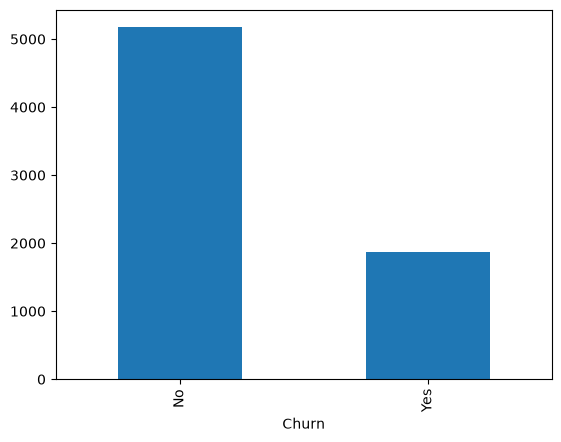

In [112]:
df['Churn'].value_counts().plot(kind='bar')

In [113]:
import matplotlib.pyplot as plt

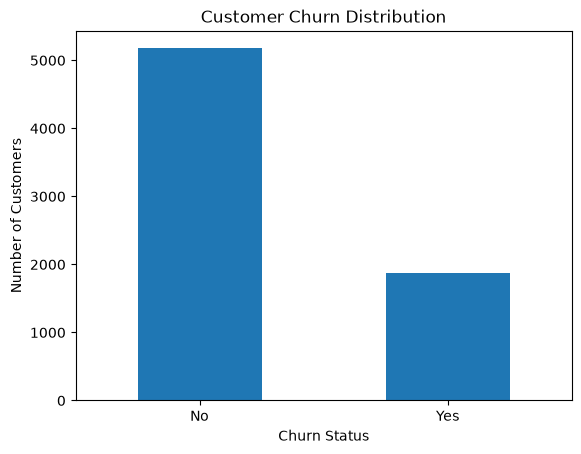

In [114]:
df['Churn'].value_counts().plot(kind='bar')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

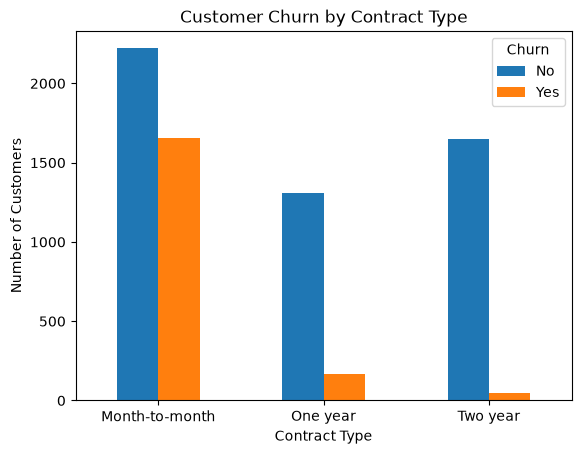

In [115]:
pd.crosstab(df['Contract'], df['Churn']).plot(kind='bar')

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

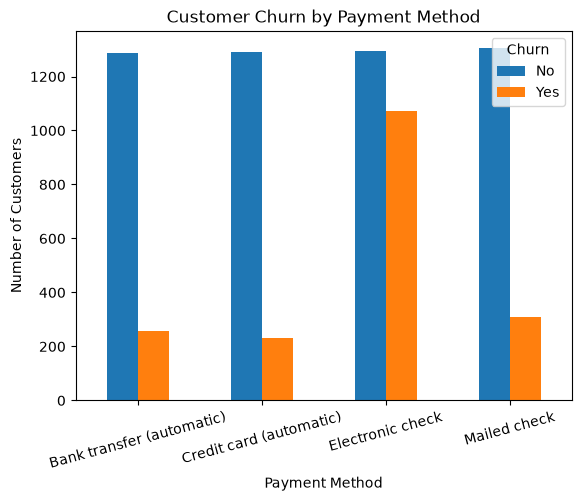

In [117]:
pd.crosstab(df['PaymentMethod'], df['Churn']).plot(kind='bar')

plt.title('Customer Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Customers')
plt.xticks(rotation=15)
plt.show()

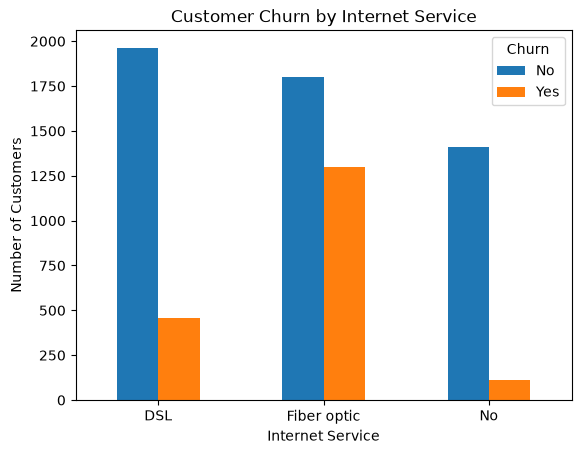

In [118]:
pd.crosstab(df['InternetService'], df['Churn']).plot(kind='bar')

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

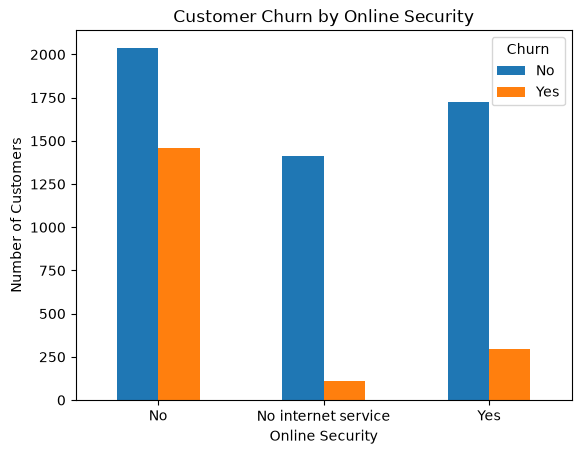

In [119]:
pd.crosstab(df['OnlineSecurity'], df['Churn']).plot(kind='bar')

plt.title('Customer Churn by Online Security')
plt.xlabel('Online Security')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

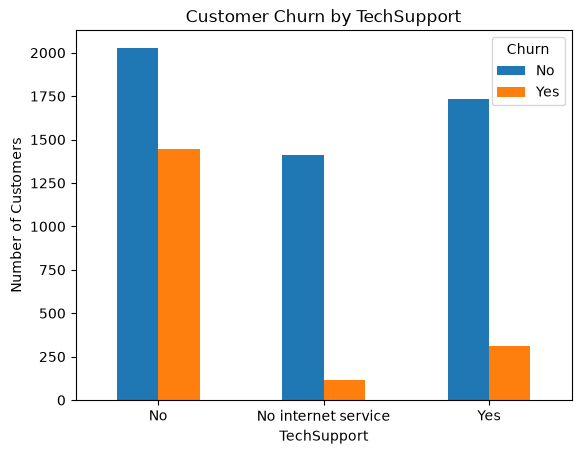

In [121]:
pd.crosstab(df['TechSupport'], df['Churn']).plot(kind='bar')

plt.title('Customer Churn by TechSupport')
plt.xlabel('TechSupport')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

In [122]:
df['TotalCharges'].isnull().sum()

np.int64(11)

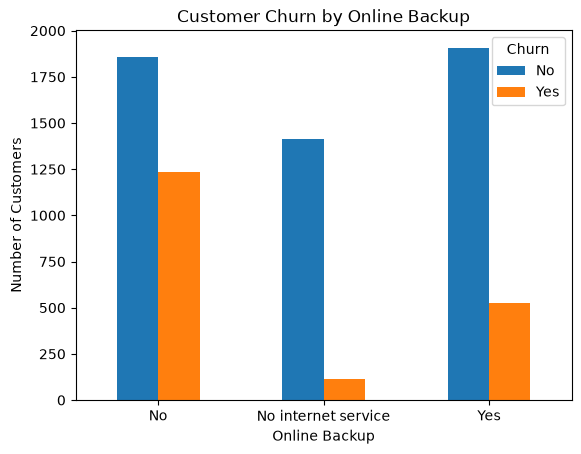

In [124]:
pd.crosstab(df['OnlineBackup'], df['Churn']).plot(kind='bar')

plt.title('Customer Churn by Online Backup')
plt.xlabel('Online Backup')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()